# ShockFlow AI 면접용 워크스루: 데이터 → EDA → 예측(WAPE) → 최적화

이 노트북은 **흐름을 설명하기 위한 것**입니다. 실제 저장소 함수(수집기, 피처 빌더, 지표, 솔버)를 그대로 부르되,
입력 데이터는 Citi Bike 스키마를 따르는 **합성 CSV**를 셀 안에서 만들어 씁니다. 그래서 여기서 나오는 숫자는
`demo_fixture` / `simulated` 성격이고, 포트폴리오에 적는 실측값은 마지막 절에서 `reports/` 아티팩트를 읽어 따로 보여줍니다.

| 단계 | 저장소 모듈 | 이 노트북에서 하는 일 |
|---|---|---|
| 1. 데이터 | `pipelines.collectors.CitiBikeCollector` | 합성 트립 CSV 생성, 수집기 검증 통과 |
| 2. EDA | `pipelines.features.aggregate_demand` | H3 zone × 시간 집계, 시간대 프로파일, 이벤트 날 스파이크 |
| 3. 피처 | `ml.forecasting.dataset.load_real_panel` | 지연/롤링 피처 + 뉴스 fixture → LLM(mock) 이벤트 피처 as-of 조인 |
| 4. 예측 | `ml.forecasting.*` | B0 seasonal naive → B1 → B3 → B4, WAPE/MAE/MASE/OCS |
| 5. 최적화 | `optimization.classical`, `optimization.mpc` | greedy vs MILP (단일 시점), no_action/greedy/milp/mpc/oracle (다기간) |
| 6. 실측 | `reports/v2/**` | 실제 포트폴리오 숫자와 claim_status |

실행 방법: 저장소 루트에서 `jupyter lab notebooks/interview_walkthrough.ipynb` (의존성은 `make install`).

In [1]:
from __future__ import annotations

import json
import sys
import warnings
from datetime import datetime, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# 노트북이 notebooks/ 안에 있으므로 저장소 루트를 찾아 cwd 와 sys.path 로 잡는다.
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), ROOT
import os; os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUT = ROOT / "notebooks" / "outputs"   # .gitignore 대상
OUT.mkdir(parents=True, exist_ok=True)
NY = ZoneInfo("America/New_York")
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160, "display.max_columns", 60)
warnings.filterwarnings("ignore", category=FutureWarning)

# 그래프 한글: 설치된 폰트 중 하나를 고른다 (없으면 영문 라벨만 깨끗하게 나오도록 경고를 끈다).
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR", "WenQuanYi Zen Hei"]:
    if _f in _installed:
        plt.rcParams["font.family"] = _f
        break
plt.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
print("repo root:", ROOT)

repo root: /home/user/AI_Pro_project


## 1. 데이터: Citi Bike 스키마의 합성 트립 CSV

실제 입력은 Citi Bike 공개 트립 이력(`data/raw/citibike/*.zip`)입니다. 컬럼은 아래와 같고, 수집기는 좌표 결측, 역전된 시각,
비정상 길이 같은 행을 **버리지 않고 사유별로 세서 메타데이터에 남깁니다**.

합성 시나리오: 저지시티/호보켄 6개 정류장, 2026-06-01 ~ 2026-07-14. 평일 출퇴근 패턴에 포아송 잡음을 얹고,
**PATH 운행 중단(14~19시) + 저녁 공연** 충격을 6일에 심어 둡니다. 다섯 번은 학습 구간(6월), 마지막 한 번은 뉴스 fixture(`data/fixtures/news_demo.jsonl`)와 같은 2026-07-12 로 테스트 구간입니다.
같은 날짜에 맞춘 뉴스 JSONL 도 fixture 형식 그대로 만들어 둡니다(문장은 fixture 의 것을 재사용).

In [2]:
STATIONS = pd.DataFrame(
    [
        ("HB101", "Grove St PATH",     40.7196, -74.0431, 14.0),
        ("HB102", "Hoboken Terminal",  40.7360, -74.0301, 16.0),
        ("HB105", "City Hall",         40.7377, -74.0324,  8.0),
        ("HB110", "Newport Pkwy",      40.7285, -74.0320,  9.0),
        ("HB120", "Exchange Pl",       40.7162, -74.0334, 11.0),
        ("HB130", "Hamilton Park",     40.7275, -74.0444,  6.0),
    ],
    columns=["station_id", "name", "lat", "lng", "base_rate"],
)

def hourly_profile(hour: int, weekend: bool) -> float:
    # 출퇴근 두 봉우리(평일) vs 완만한 오후 봉우리(주말), 값은 0~1 사이의 배율
    if weekend:
        return 0.15 + 0.85 * np.exp(-((hour - 14) ** 2) / 18.0)
    am = np.exp(-((hour - 8) ** 2) / 3.0)
    pm = np.exp(-((hour - 18) ** 2) / 4.0)
    return 0.08 + 0.9 * max(am, pm)

EVENT_DAY = datetime(2026, 7, 12, tzinfo=NY)                      # 뉴스 fixture 와 같은 날 (일요일) → 테스트 구간
# 학습 구간에도 같은 종류의 충격이 몇 번 있어야 모델이 이벤트 피처를 배울 수 있다 (실데이터에서도 똑같은 조건).
EVENT_DAYS = [datetime(2026, 6, d, tzinfo=NY).date() for d in (6, 13, 20, 27)] + [datetime(2026, 7, 3, tzinfo=NY).date(), EVENT_DAY.date()]
SHOCK = {"HB101": 2.6, "HB102": 3.0, "HB105": 2.2}                 # PATH 중단 → 터미널 주변 출발 급증 (14~19시)
CONCERT = {"HB110": 2.0}                                            # 저녁 Newport 공연 (18~22시)

def shock_multiplier(station_id: str, ts: datetime) -> float:
    if ts.date() not in EVENT_DAYS:
        return 1.0
    if station_id in SHOCK and 14 <= ts.hour < 19:
        return SHOCK[station_id]
    if station_id in CONCERT and 18 <= ts.hour < 22:
        return CONCERT[station_id]
    return 1.0

start, end = datetime(2026, 6, 1, tzinfo=NY), datetime(2026, 7, 15, tzinfo=NY)
hours = pd.date_range(start, end, freq="h", inclusive="left", tz=NY)

rows = []
ride = 0
for ts in hours:
    weekend = ts.weekday() >= 5
    for s in STATIONS.itertuples(index=False):
        lam = s.base_rate * hourly_profile(ts.hour, weekend) * shock_multiplier(s.station_id, ts)
        n = rng.poisson(lam)
        if n == 0:
            continue
        dest = STATIONS[STATIONS.station_id != s.station_id].sample(n, replace=True, random_state=int(rng.integers(1 << 31)))
        starts = ts + pd.to_timedelta(rng.integers(0, 3600, n), unit="s")
        durs = pd.to_timedelta(rng.integers(5 * 60, 30 * 60, n), unit="s")
        for k in range(n):
            ride += 1
            d = dest.iloc[k]
            rows.append(
                dict(
                    ride_id=f"R{ride:016d}",
                    rideable_type="electric_bike" if rng.random() < 0.35 else "classic_bike",
                    started_at=starts[k].strftime("%Y-%m-%d %H:%M:%S"),
                    ended_at=(starts[k] + durs[k]).strftime("%Y-%m-%d %H:%M:%S"),
                    start_station_id=s.station_id, start_station_name=s.name,
                    end_station_id=d.station_id, end_station_name=d["name"],
                    start_lat=s.lat, start_lng=s.lng, end_lat=d.lat, end_lng=d.lng,
                    member_casual="member" if rng.random() < 0.72 else "casual",
                )
            )

trips = pd.DataFrame(rows)

# 일부러 섞는 불량 행: 좌표 결측, 종료 < 시작, 비정상 좌표. 수집기가 어떻게 보고하는지 보기 위함.
bad = trips.sample(30, random_state=SEED).copy()
bad.iloc[:10, bad.columns.get_loc("start_lat")] = np.nan
bad.iloc[10:20, bad.columns.get_loc("ended_at")] = "2026-05-01 00:00:00"
bad.iloc[20:, bad.columns.get_loc("start_lat")] = 999.0
bad["ride_id"] = [f"BAD{i:03d}" for i in range(len(bad))]
trips = pd.concat([trips, bad], ignore_index=True).sample(frac=1.0, random_state=SEED)

CSV = OUT / "trips_synthetic.csv"
trips.to_csv(CSV, index=False)
print(f"{len(trips):,} rows -> {CSV.relative_to(ROOT)}")

# 뉴스도 같은 날짜들에 맞춰 fixture 와 같은 JSONL 형식으로 만든다 (문장은 data/fixtures/news_demo.jsonl 의 a2/a3 를 그대로 재사용).
# 핵심 필드: published_at(공개 시각), first_seen_at(시스템이 처음 본 시각) → available_at = max(둘) 이 조인 기준.
# 추출기는 같은 타입에서 제목 토큰 Jaccard >= 0.6 이면 같은 이벤트로 합친다(중복 기사 처리).
# 그래서 날짜마다 표현을 바꿔 "다른 날의 다른 사건"이 되게 한다. 마지막(7/12)은 fixture 문장 그대로.
PATH_TITLES = [
    "PATH trains halted between Hoboken Terminal and City Hall after signal failure",
    "Afternoon disruption: no service on PATH at Hoboken Terminal",
    "Hoboken Terminal PATH riders face delays as service is suspended",
    "Suspended: PATH service between City Hall and Hoboken Terminal this afternoon",
    "Signal problems force PATH service change near Hoboken Terminal and City Hall",
    "Signal failure suspends PATH service near Hoboken Terminal",
]
CONCERT_TITLES = [
    "Newport festival lineup announced for tonight",
    "Sold out show tonight at the Newport waterfront stage",
    "Evening concert series returns to Newport",
    "Thousands expected at Newport waterfront festival",
    "Summer concert on the Hudson waterfront at Newport tonight",
    "Waterfront concert expected to draw large crowds",
]
PATH_TEXT = "A signal failure has suspended PATH service between Hoboken Terminal and City Hall, effective this afternoon."
CONCERT_TEXT = "A large evening concert at the Newport waterfront is expected to draw thousands."
NEWS = OUT / "news_synthetic.jsonl"
with NEWS.open("w", encoding="utf-8") as fh:
    for i, day in enumerate(EVENT_DAYS):
        base = datetime(day.year, day.month, day.day, tzinfo=NY)
        for j, (title, text, source, pub_h, seen_h) in enumerate([
            (PATH_TITLES[i], PATH_TEXT, "demo_wire", 14, 13.5),      # 공개 14:00, 시스템 관측 13:30 → available 14:00
            (CONCERT_TITLES[i], CONCERT_TEXT, "demo_events", 15, 14.5),
        ]):
            fh.write(json.dumps(dict(
                article_id=f"syn_{i}_{j}", title=title, text=text, source=source,
                published_at=(base + timedelta(hours=pub_h)).isoformat(),
                first_seen_at=(base + timedelta(hours=seen_h)).isoformat(),
                url_hash=f"hash_syn_{i}_{j}")) + "\n")
print(f"{2 * len(EVENT_DAYS)} articles -> {NEWS.relative_to(ROOT)}")
trips.head(8)

25,497 rows -> notebooks/outputs/trips_synthetic.csv
12 articles -> notebooks/outputs/news_synthetic.jsonl


,ride_id,rideable_type,started_at,ended_at,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,member_casual
6912,R0000000000006913,classic_bike,2026-06-13 13:56:08,2026-06-13 14:18:17,HB101,Grove St PATH,HB120,Exchange Pl,40.7196,-74.0431,40.7162,-74.0334,member
6934,R0000000000006935,classic_bike,2026-06-13 13:06:56,2026-06-13 13:25:13,HB105,City Hall,HB101,Grove St PATH,40.7377,-74.0324,40.7196,-74.0431,member
14441,R0000000000014442,electric_bike,2026-06-26 09:42:32,2026-06-26 10:02:17,HB120,Exchange Pl,HB102,Hoboken Terminal,40.7162,-74.0334,40.7360,-74.0301,member
2764,R0000000000002765,classic_bike,2026-06-06 11:41:34,2026-06-06 12:09:49,HB110,Newport Pkwy,HB101,Grove St PATH,40.7285,-74.0320,40.7196,-74.0431,member
23213,R0000000000023214,classic_bike,2026-07-11 14:27:14,2026-07-11 14:45:43,HB102,Hoboken Terminal,HB120,Exchange Pl,40.7360,-74.0301,40.7162,-74.0334,member
11251,R0000000000011252,classic_bike,2026-06-20 16:37:44,2026-06-20 16:48:44,HB102,Hoboken Terminal,HB130,Hamilton Park,40.7360,-74.0301,40.7275,-74.0444,member
3073,R0000000000003074,classic_bike,2026-06-06 15:09:57,2026-06-06 15:14:57,HB102,Hoboken Terminal,HB101,Grove St PATH,40.7360,-74.0301,40.7196,-74.0431,member
12056,R0000000000012057,electric_bike,2026-06-21 16:16:59,2026-06-21 16:31:41,HB120,Exchange Pl,HB105,City Hall,40.7162,-74.0334,40.7377,-74.0324,casual


In [3]:
from pipelines.collectors import CitiBikeCollector

result = CitiBikeCollector(CSV).collect()
meta = result.metadata
print(f"accepted {meta.accepted_rows:,} / total {meta.total_rows:,}  (excluded {meta.excluded_rows})")
print("exclusion reasons:", json.dumps(meta.exclusion_reasons, indent=2))
print("mode:", meta.mode, "| schema_hash:", meta.schema_hash)
t0 = result.records[0]
print("first TripRecord:", t0.started_at.isoformat(), "->", t0.ended_at.isoformat(), t0.start_station_id, "->", t0.end_station_id)

accepted 25,467 / total 25,497  (excluded 30)
exclusion reasons: {
  "coordinate_out_of_range": 10,
  "end_before_start": 10,
  "missing_coordinate": 10
}
mode: demo_fixture | schema_hash: d11caa1d3e4a4e3e37410f7f3fe58418853032377390402917daa9ba5a9c8429
first TripRecord: 2026-06-13T13:56:08-04:00 -> 2026-06-13T14:18:17-04:00 HB101 -> HB120


## 2. EDA: H3 zone × 시간 수요 패널

예측의 기본 단위는 **H3 zone(해상도 9) × 현지 시간(America/New_York) 1시간**입니다.
타깃은 `departures`, `arrivals`, `net_flow = arrivals - departures` 세 개이고, 정류장별 집계가 아니라 zone 단위로 합칩니다.

In [4]:
from pipelines.features import aggregate_demand

cells = aggregate_demand(result.records)
demand = pd.DataFrame([c.model_dump() for c in cells]).sort_values(["hour_start", "zone_id"]).reset_index(drop=True)
demand["hour_start"] = pd.to_datetime(demand["hour_start"], utc=True).dt.tz_convert(NY)
print(f"{len(demand):,} zone-hour cells, {demand.zone_id.nunique()} H3 zones, "
      f"{demand.hour_start.min()} ~ {demand.hour_start.max()}")
demand.head()

5,954 zone-hour cells, 6 H3 zones, 2026-06-01 00:00:00-04:00 ~ 2026-07-15 00:00:00-04:00


,zone_id,hour_start,departures,arrivals,net_flow,departures_member,departures_casual,mode
0,892a107216bffff,2026-06-01 00:00:00-04:00,2,2,0,1,1,demo_fixture
1,892a10723b7ffff,2026-06-01 00:00:00-04:00,1,1,0,0,1,demo_fixture
2,892a1072e3bffff,2026-06-01 00:00:00-04:00,1,0,-1,0,1,demo_fixture
3,892a1072e5bffff,2026-06-01 00:00:00-04:00,1,0,-1,1,0,demo_fixture
4,892a1072e7bffff,2026-06-01 00:00:00-04:00,2,1,-1,1,1,demo_fixture


In [5]:
print("zone 별 총 출발 수 (정류장 → H3 zone 매핑 결과)")
zone_tot = demand.groupby("zone_id")[["departures", "arrivals"]].sum().sort_values("departures", ascending=False)
display(zone_tot)
demand[["departures", "arrivals", "net_flow"]].describe().T

zone 별 총 출발 수 (정류장 → H3 zone 매핑 결과)


,departures,arrivals
zone_id,,
892a107216bffff,6653,3780
892a1072e7bffff,5635,3968
892a1072e3bffff,4162,4243
892a1072ec7ffff,3496,4367
892a10723b7ffff,3262,4367
892a1072e5bffff,2259,4742


,count,mean,std,min,25%,50%,75%,max
departures,5954.0,4.277293,5.137079,0.0,1.0,3.0,6.0,53.0
arrivals,5954.0,4.277293,4.297660,0.0,1.0,3.0,6.0,33.0
net_flow,5954.0,0.000000,4.322541,-43.0,-2.0,0.0,2.0,25.0


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


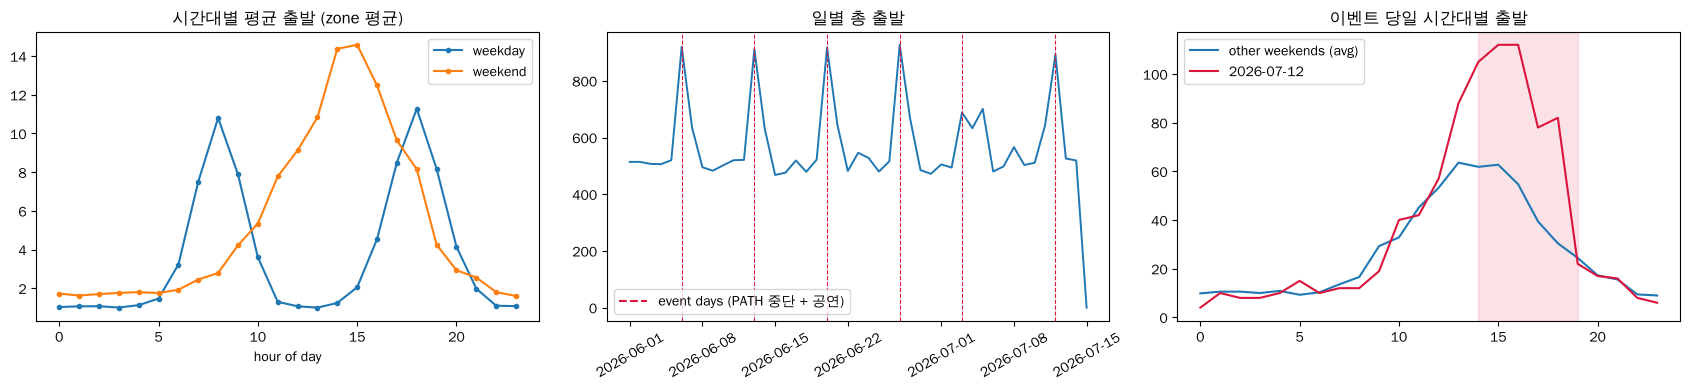

In [6]:
demand["hour"] = demand.hour_start.dt.hour
demand["weekend"] = demand.hour_start.dt.weekday >= 5
demand["date"] = demand.hour_start.dt.date

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

prof = demand.groupby(["weekend", "hour"]).departures.mean().unstack(0)
prof.plot(ax=axes[0], marker="o", ms=3)
axes[0].set_title("시간대별 평균 출발 (zone 평균)"); axes[0].set_xlabel("hour of day"); axes[0].legend(["weekday", "weekend"])

daily = demand.groupby("date").departures.sum()
axes[1].plot(pd.to_datetime(daily.index), daily.values, lw=1.4)
for d in EVENT_DAYS:
    axes[1].axvline(pd.Timestamp(d), color="crimson", ls="--", lw=0.8)
axes[1].plot([], [], color="crimson", ls="--", label="event days (PATH 중단 + 공연)")
axes[1].set_title("일별 총 출발"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=30)

ev = demand[demand.date == EVENT_DAY.date()].groupby("hour").departures.sum()
quiet = demand[(demand.weekend) & (~demand.date.isin(EVENT_DAYS))]
base = quiet.groupby("hour").departures.sum() / quiet.date.nunique()
axes[2].plot(base.index, base.values, label="other weekends (avg)")
axes[2].plot(ev.index, ev.values, label="2026-07-12", color="crimson")
axes[2].axvspan(14, 19, alpha=0.12, color="crimson"); axes[2].set_title("이벤트 당일 시간대별 출발"); axes[2].legend()
plt.tight_layout(); plt.show()

findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


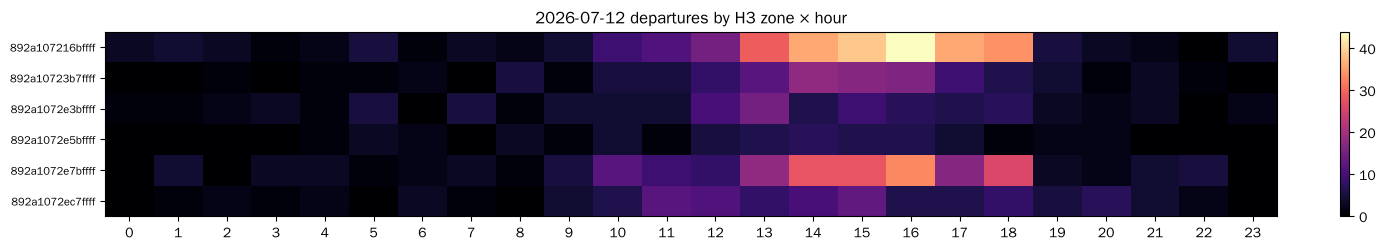

In [7]:
# 이벤트 시간대 zone × hour 히트맵: 어느 zone 에 충격이 집중되는지
pivot = demand[demand.date == EVENT_DAY.date()].pivot_table(index="zone_id", columns="hour", values="departures", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(figsize=(14, 2.6))
im = ax.imshow(pivot.values, aspect="auto", cmap="magma")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=8)
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_title("2026-07-12 departures by H3 zone × hour"); plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.show()

## 3. 피처 패널: 지연/롤링 + 뉴스 → LLM 이벤트 피처 as-of 조인

`load_real_panel` 은 수집 → 집계 → 피처 → 뉴스 조인을 한 번에 합니다. 기사(JSONL)는 `available_at = max(published_at, first_seen_at)` 로 정렬해
**예측 cutoff 이전에 공개된 기사만** 그 시간 행에 합쳐집니다(누수 방지 규칙). 여기서는 결정적 `mock` 제공자를 써서 API 키 없이 돌립니다.

컬럼 묶음(ablation 단계):

- **B1** 수요 이력 + 달력 (`dep_lag_*`, `dep_roll_*`, hour/dow 등)
- **B2** + 기사 수 (`article_count_6h/24h`)
- **B3** + LLM 이벤트 피처 (`event_severity_sum`, `event_confidence_mean`, `transit_disruption_flag`)
- **B4** + 그래프 전파 피처 (`graph_distance_decayed_impact`, `graph_neighbor_zone_impact`, `graph_transit_exposure`)

In [8]:
# LLM 추출 단계만 따로 보기: 기사 → (타입, 장소, 시각, 심각도 prior, 신뢰도, 근거 문장). mock 제공자는 키워드/지명 사전 기반의 결정적 구현.
from pipelines.collectors import NewsFixtureCollector
from pipelines.events import build_provider, extract_events

articles = NewsFixtureCollector(NEWS).collect().records
events, run_meta = extract_events(articles, build_provider("mock"))
print(run_meta)
pd.DataFrame([dict(event_id=e.event_id[:12], type=e.event_type.value, available_at=e.available_at.strftime("%m-%d %H:%M"),
                   places=[l.name for l in e.locations], severity=e.severity, confidence=e.confidence, status=e.status.value,
                   evidence=e.evidence_spans[0].text[:60] if e.evidence_spans else None) for e in events])

ExtractionRunMetadata(prompt_version='mock-v1', articles=12, candidates=12, accepted=12, quarantined=0, rejected=0, deduped=0, errors=[])


,event_id,type,available_at,places,severity,confidence,status,evidence
0,evt_b9013a65,TRANSIT_DISRUPTION,06-06 14:00,"[Hoboken Terminal, City Hall]",0.7,0.70,accepted,A signal failure has suspended PATH service be...
1,evt_8b463eb3,LARGE_VENUE_EVENT,06-06 15:00,"[Newport, Newport Waterfront]",0.5,0.70,accepted,A large evening concert at the Newport waterfr...
2,evt_c42ce7c8,TRANSIT_DISRUPTION,06-13 14:00,"[Hoboken Terminal, City Hall]",0.7,0.90,accepted,A signal failure has suspended PATH service be...
3,evt_48e7b506,LARGE_VENUE_EVENT,06-13 15:00,"[Newport, Newport Waterfront]",0.5,0.70,accepted,A large evening concert at the Newport waterfr...
4,evt_f57fac82,TRANSIT_DISRUPTION,06-20 14:00,"[Hoboken Terminal, City Hall]",0.7,0.85,accepted,A signal failure has suspended PATH service be...
5,evt_11c04601,LARGE_VENUE_EVENT,06-20 15:00,"[Newport, Newport Waterfront]",0.5,0.55,accepted,A large evening concert at the Newport waterfr...
6,evt_22b4f49b,TRANSIT_DISRUPTION,06-27 14:00,"[Hoboken Terminal, City Hall]",0.7,0.70,accepted,A signal failure has suspended PATH service be...
7,evt_2ebabc53,LARGE_VENUE_EVENT,06-27 15:00,"[Newport, Newport Waterfront]",0.5,0.70,accepted,A large evening concert at the Newport waterfr...
8,evt_f59ffcb6,TRANSIT_DISRUPTION,07-03 14:00,"[Hoboken Terminal, City Hall]",0.7,0.85,accepted,A signal failure has suspended PATH service be...
9,evt_1e6ec0ab,LARGE_VENUE_EVENT,07-03 15:00,"[Newport, Newport Waterfront]",0.5,0.55,accepted,A large evening concert at the Newport waterfr...


In [9]:
from ml.forecasting.dataset import load_real_panel

panel = load_real_panel(CSV, news_source=NEWS, provider="mock")   # NEWS: 위에서 만든 합성 JSONL (fixture 형식)
df = panel.df.copy()
df["hour_start"] = pd.to_datetime(df["hour_start"], utc=True).dt.tz_convert(NY)

print("rows:", len(df), "| columns:", len(df.columns))
print("B1 cols (%d):" % len(panel.b1_cols), panel.b1_cols)
for k, v in panel.extra_cols.items():
    print(f"{k:8s}:", list(v))

rows: 5954 | columns: 45
B1 cols (32): ['arr_expanding_mean', 'arr_lag_1', 'arr_lag_168', 'arr_lag_24', 'arr_momentum', 'arr_roll_mean_24', 'arr_roll_mean_3', 'cal_day_of_week', 'cal_dow_cos', 'cal_dow_sin', 'cal_hour_cos', 'cal_hour_of_day', 'cal_hour_sin', 'cal_is_evening_rush', 'cal_is_holiday', 'cal_is_morning_rush', 'cal_is_weekend', 'dep_expanding_mean', 'dep_lag_1', 'dep_lag_168', 'dep_lag_24', 'dep_momentum', 'dep_roll_mean_24', 'dep_roll_mean_3', 'member_share_lag_168', 'member_share_lag_24', 'net_cumsum_day', 'net_lag_1', 'net_lag_168', 'net_lag_24', 'net_roll_mean_24', 'net_roll_mean_3']
article : ['article_count_6h', 'article_count_24h']
event   : ['event_severity_sum', 'event_confidence_mean', 'transit_disruption_flag']
graph   : ['graph_distance_decayed_impact', 'graph_neighbor_zone_impact', 'graph_transit_exposure']


In [10]:
# 누수 검사: PATH 기사는 published 14:00 / first_seen 13:30 → available_at 14:00.
# 따라서 13시 행에는 이벤트 피처가 0, 14시 행부터 값이 생겨야 한다.
ev_cols = list(panel.extra_cols["article"]) + list(panel.extra_cols["event"]) + list(panel.extra_cols["graph"])
day = df[(df.hour_start.dt.date == EVENT_DAY.date()) & (df.hour_start.dt.hour.between(12, 17))]
show = day.groupby("hour_start")[ev_cols].max().round(3)
show.index = show.index.strftime("%m-%d %H:%M")
show

,article_count_6h,article_count_24h,event_severity_sum,event_confidence_mean,transit_disruption_flag,graph_distance_decayed_impact,graph_neighbor_zone_impact,graph_transit_exposure
hour_start,,,,,,,,
07-12 12:00,0.0,0.0,0.000,0.720,0.0,0.000,0.000,0.000
07-12 13:00,0.0,0.0,0.000,0.720,0.0,0.000,0.000,0.000
07-12 14:00,1.0,1.0,0.700,0.718,1.0,0.671,1.572,0.671
07-12 15:00,2.0,2.0,1.124,0.704,1.0,0.779,1.963,0.598
07-12 16:00,2.0,2.0,0.976,0.704,1.0,0.685,1.720,0.532
07-12 17:00,2.0,2.0,0.849,0.704,1.0,0.602,1.509,0.474


In [11]:
one = day[day.hour_start.dt.hour == 15].sort_values("graph_distance_decayed_impact", ascending=False).iloc[0]
cols = ["zone_id", "hour_start", "departures", "dep_lag_1", "dep_lag_24", "dep_lag_168", "dep_roll_mean_24"] + ev_cols
print("15시 행 하나를 펼쳐 본 모습 (한 행 = zone × hour):")
one[cols].to_frame("value")

15시 행 하나를 펼쳐 본 모습 (한 행 = zone × hour):


,value
zone_id,892a107216bffff
hour_start,2026-07-12 15:00:00-04:00
departures,39
dep_lag_1,36.0
dep_lag_24,15.0
dep_lag_168,26.0
dep_roll_mean_24,8.041667
article_count_6h,2.0
article_count_24h,2.0
event_severity_sum,1.123629


## 4. 예측: seasonal naive → 트리 모델, WAPE 가 얼마나 줄어드는지

- 분할은 **시간 기준 holdout** 입니다(랜덤 분할 금지). 7월 8일 이후를 테스트로 두어 이벤트 날(7월 12일)이 테스트에 들어가게 합니다.
- B0 는 주간 seasonal naive(`dep_lag_168`, 없으면 24h, 1h 순 fallback)입니다.
- 지표: WAPE, MAE, MASE(주기 168의 naive in-sample MAE 로 스케일), OCS(부족 2 : 과잉 1 가중 비용).
- 전체와 **이벤트 시간대(7/12 14~19시)** 를 따로 봅니다. 충격 시간대에서 이벤트 피처의 효과가 드러나는지가 핵심입니다.

In [12]:
from ml.forecasting.experiment import usable_frame
from ml.forecasting.splits import holdout_by_time
from ml.forecasting.baselines import seasonal_naive_predict
from ml.forecasting.models import make_pipeline
from ml.forecasting.metrics import wape, mae, mase, operational_cost_score
from config.forecasting import SHORTAGE_COST, OVERFLOW_COST, SEASONAL_PERIOD_H

use = usable_frame(panel)                       # 첫 주(warm-up, lag_168 없음) 제거
use["hour_start"] = pd.to_datetime(use["hour_start"], utc=True).dt.tz_convert(NY)
TEST_START = datetime(2026, 7, 8, tzinfo=NY)
dev_pos, test_pos = holdout_by_time(list(use["hour_start"]), TEST_START)
train, test = use.iloc[dev_pos], use.iloc[test_pos]
y_tr, y_te = train["departures"].to_numpy(float), test["departures"].to_numpy(float)
print(f"train {len(train):,} rows (~{train.hour_start.min():%m-%d} .. {train.hour_start.max():%m-%d}) | "
      f"test {len(test):,} rows ({test.hour_start.min():%m-%d} .. {test.hour_start.max():%m-%d})")

# MASE 분모: 학습 구간의 주간 seasonal naive in-sample MAE (|y_t - y_{t-168}|)
scale = float(np.nanmean(np.abs(train["departures"] - train["dep_lag_168"])))
ev_mask = ((test.hour_start.dt.date == EVENT_DAY.date()) & test.hour_start.dt.hour.between(14, 18)).to_numpy()
print(f"seasonal scale = {scale:.3f} | event-window test rows = {ev_mask.sum()}")

def score(name: str, pred: np.ndarray) -> dict:
    pred = np.clip(pred, 0, None)
    return {
        "model": name,
        "WAPE": wape(y_te, pred), "MAE": mae(y_te, pred), "MASE": mase(y_te, pred, scale),
        "OCS": operational_cost_score(y_te, pred, shortage_cost=SHORTAGE_COST, overflow_cost=OVERFLOW_COST)["ocs"],
        "WAPE_event_window": wape(y_te[ev_mask], pred[ev_mask]),
    }

preds = {"B0 seasonal naive": seasonal_naive_predict(test)}
for level, label in [("B1", "B1 history+calendar"), ("B2", "B2 +article counts"), ("B3", "B3 +LLM event"), ("B4", "B4 +graph")]:
    cols = panel.ablation_cols(level)
    pipe, _grid = make_pipeline("hist_gradient_boosting")
    pipe.set_params(model__random_state=SEED)
    pipe.fit(train[cols].to_numpy(float), y_tr)
    preds[label] = pipe.predict(test[cols].to_numpy(float))

scores = pd.DataFrame([score(k, v) for k, v in preds.items()]).set_index("model")
scores.round(4)

train 4,041 rows (~06-08 .. 07-07) | test 953 rows (07-08 .. 07-15)
seasonal scale = 2.075 | event-window test rows = 30


,WAPE,MAE,MASE,OCS,WAPE_event_window
model,,,,,
B0 seasonal naive,0.5489,2.3966,1.1552,0.8484,0.5501
B1 history+calendar,0.4256,1.8582,0.8956,0.6476,0.3342
B2 +article counts,0.4186,1.8277,0.8809,0.6497,0.3455
B3 +LLM event,0.4218,1.8419,0.8878,0.6430,0.3285
B4 +graph,0.4174,1.8224,0.8784,0.6391,0.3134


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


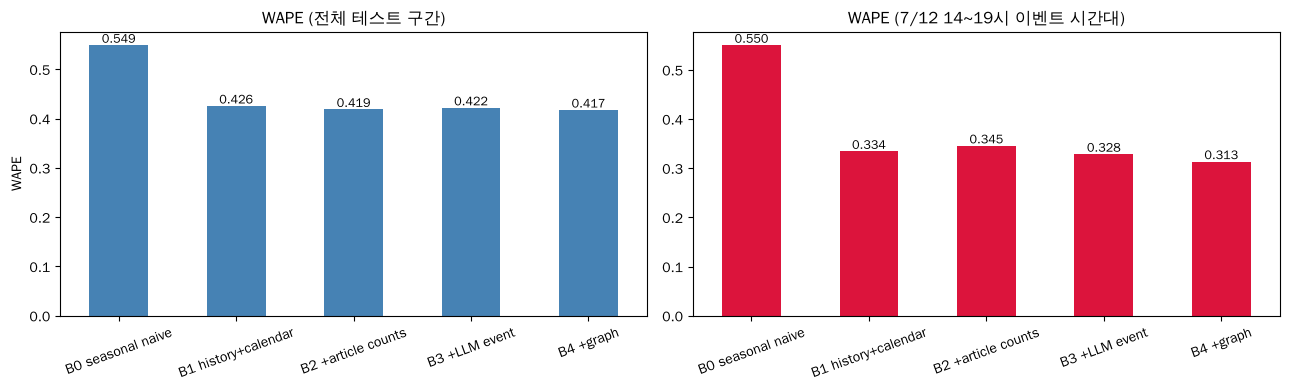

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
scores["WAPE"].plot.bar(ax=axes[0], color="steelblue"); axes[0].set_title("WAPE (전체 테스트 구간)"); axes[0].set_ylabel("WAPE")
scores["WAPE_event_window"].plot.bar(ax=axes[1], color="crimson"); axes[1].set_title("WAPE (7/12 14~19시 이벤트 시간대)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

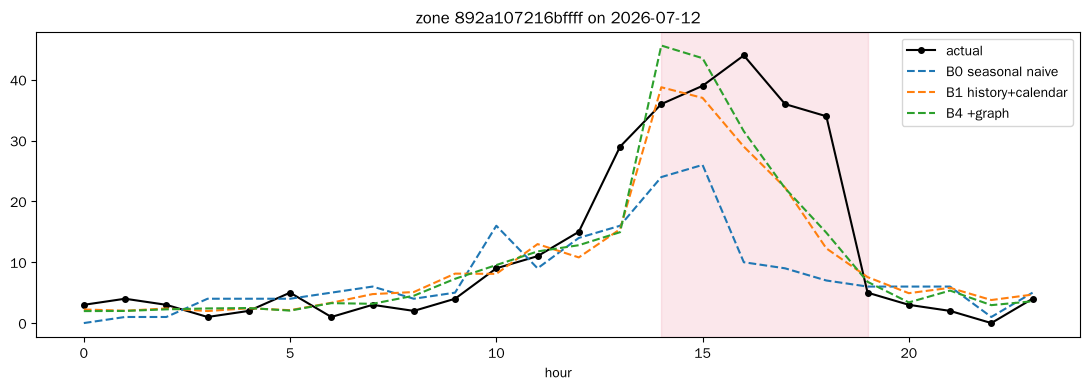

In [14]:
# 이벤트 날 충격 zone 의 실제 vs 예측 시계열: 이벤트 피처가 있어야 14시 이후 급증을 따라가는지
zone_hot = one["zone_id"]
m = (test.zone_id == zone_hot) & (test.hour_start.dt.date == EVENT_DAY.date())
t = test[m].hour_start.dt.hour
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, y_te[m.to_numpy()], "k-o", ms=4, label="actual")
for k in ["B0 seasonal naive", "B1 history+calendar", "B4 +graph"]:
    ax.plot(t, np.clip(preds[k][m.to_numpy()], 0, None), "--", label=k)
ax.axvspan(14, 19, alpha=0.1, color="crimson"); ax.set_title(f"zone {zone_hot} on 2026-07-12"); ax.set_xlabel("hour"); ax.legend()
plt.tight_layout(); plt.show()

### 왜 여기서는 B3/B4 가 좋아 보이는가, 그리고 실측에서는 어땠는가

이 합성 데이터는 뉴스의 이벤트와 **같은 시간에 같은 zone 에** 수요 충격을 심어 두었고, 학습 구간에 같은 충격이 다섯 번 있었기 때문에 이벤트 피처가 거의 정답지 역할을 합니다.
(처음 이 노트북을 만들 때 이벤트를 테스트 날 하루에만 넣었더니 B1~B4 가 완전히 같은 값이 나왔습니다. 학습 구간에서 늘 0 인 피처는 트리가 쓸 수 없기 때문입니다. 실제 NYC 데이터에서 LLM 뉴스 증분이 작았던 이유 중 하나도 이 희소성입니다.)
실제 NYC 데이터에서는 그렇지 않았고, 그 결과를 솔직히 적는 것이 포트폴리오의 핵심입니다(마지막 절 참고).

## 5. 최적화: 예측을 재배치 행동으로

### 5-1. 단일 시점: greedy vs MILP

예측된 출발 수요로 zone 별 목표 재고를 정하고, 현재 재고와의 차이를 **트럭 이동(정수)** 으로 메웁니다.
목적함수 = 부족 비용 + 과잉 비용 + 이동 거리 비용, 제약 = 출발지 보유량, 도착지 용량, 차량 용량, 비음수 정수.
greedy 는 가장 큰 부족부터 가까운 잉여에서 채우는 feasible 휴리스틱, MILP 는 scipy `milp`(HiGHS) 로 푸는 정확해입니다.
차량 용량(한 기간 총 이동 상한)이 작으면 두 방법이 같은 답을 내고, 상한이 커질수록 greedy 가 거리 비용에서 손해를 보기 시작합니다.
`check_feasibility` 가 모든 계획을 제약 위반 여부로 검사한 뒤에만 결과를 보여 줍니다.

In [15]:
import h3
from optimization.classical.problem import RebalancingProblem, Station
from optimization.classical.greedy import greedy_plan
from optimization.classical.milp import milp_plan
from optimization.classical.objective import plan_cost, do_nothing_cost
from optimization.classical.feasibility import check_feasibility

# 이벤트 시간(7/12 15시)의 B4 예측값 → zone 별 목표 재고. 현재 재고는 시드 난수(실제로는 GBFS station_status).
at = (test.hour_start.dt.date == EVENT_DAY.date()) & (test.hour_start.dt.hour == 15)
fc15 = pd.Series(np.clip(preds["B4 +graph"][at.to_numpy()], 0, None), index=test[at].zone_id.values)
CAP = 40
prng = np.random.default_rng(7)
hot = set(fc15.sort_values(ascending=False).index[:3])          # 예측 수요 상위 3개 zone 은 재고가 바닥난 상태로 둔다
stations = []
for z, f in fc15.items():
    lat, lng = h3.cell_to_latlng(z)
    target = int(min(CAP, np.ceil(f * 1.2) + 2))               # 예측 수요의 120% + 안전재고
    bikes = int(prng.integers(1, 6)) if z in hot else int(prng.integers(20, CAP - 3))
    stations.append(Station(station_id=z, name=z[-6:], lat=lat, lng=lng, bikes=bikes, capacity=CAP, target=target, zone_id=z))

problem = RebalancingProblem(stations=tuple(stations), vehicle_capacity=60)   # 차량 용량 = 한 기간에 옮길 수 있는 총 대수 상한
pd.DataFrame([dict(zone=s.station_id, forecast_dep=round(float(fc15[s.station_id]), 1), bikes=s.bikes, target=s.target,
                   surplus=s.surplus, deficit=s.deficit) for s in stations])

,zone,forecast_dep,bikes,target,surplus,deficit
0,892a107216bffff,43.5,5,40,0,35
1,892a10723b7ffff,18.2,4,24,0,20
2,892a1072e3bffff,10.7,31,15,16,0
3,892a1072e5bffff,4.8,35,8,27,0
4,892a1072e7bffff,23.2,3,30,0,27
5,892a1072ec7ffff,13.0,33,18,15,0


In [16]:
greedy = greedy_plan(problem)
milp, milp_cost = milp_plan(problem)

def row(name, plan):
    c = plan_cost(problem, plan)
    feas = check_feasibility(problem, plan)
    return dict(plan=name, moves=len(plan.moves), moved_units=plan.total_moved, shortage_units=c.shortage_units,
                overflow_units=c.overflow_units, distance_km=round(c.distance_km, 2), total_cost=round(c.total_cost, 2),
                feasible=feas.feasible, violations=feas.reason)

compare = pd.DataFrame([
    dict(plan="do_nothing", moves=0, moved_units=0, shortage_units=do_nothing_cost(problem).shortage_units,
         overflow_units=do_nothing_cost(problem).overflow_units, distance_km=0.0,
         total_cost=round(do_nothing_cost(problem).total_cost, 2), feasible=True, violations=None),
    row("greedy", greedy), row("milp", milp),
]).set_index("plan")
display(compare)
print("MILP moves:")
pd.DataFrame([m.__dict__ for m in milp.moves])

,moves,moved_units,shortage_units,overflow_units,distance_km,total_cost,feasible,violations
plan,,,,,,,,
do_nothing,0,0,82,58,0.00,304.00,True,None
greedy,3,58,24,0,70.80,107.40,True,None
milp,4,58,24,0,63.21,103.61,True,None


MILP moves:


,origin_id,destination_id,quantity,distance_km
0,892a1072e3bffff,892a1072e7bffff,16,0.9460
1,892a1072e5bffff,892a107216bffff,16,1.5428
2,892a1072e5bffff,892a1072e7bffff,11,0.8984
3,892a1072ec7ffff,892a107216bffff,15,0.9005


### 5-2. 다기간: No Action / Greedy / MILP / MPC / Oracle

실제 운영은 매 시간 반복됩니다. `optimization.mpc.simulate` 는 매 시간 정책이 목표 재고를 정하고(예측만 사용), 재배치 후 실현 수요가 들어와
부족/과잉이 **V2-02 ledger 비용**(가정값: 부족 1.00, 과잉 0.30, 이동 0.40, `config/v2/assumptions.yaml`, `sourced: false`)으로 집계됩니다.

- Greedy/MILP: 1시간 앞 예측으로 목표
- MPC: 6시간 앞 예측 합으로 목표 (receding horizon), 정확해
- Oracle: 실현 수요를 미리 아는 오프라인 상한 → `regret = total_cost − Oracle total_cost`

수요는 저장소에 문서화된 **시드 고정 통근 시나리오**(8 zone × 72시간)이므로 결과는 `simulated` 입니다.

In [17]:
from optimization.mpc import default_network, demand_series, simulate
from optimization.ledger_run import load_assumptions

A = load_assumptions()
zones = default_network(8)
fc, realized = demand_series(zones, hours=72, seed=SEED)
print(f"assumptions {A.version} (sourced={A.sourced}): shortage {A.shortage_externality}, overflow {A.overflow_penalty}, "
      f"reposition {A.reposition_cost_per_unit}")

res = {p: simulate(p, zones, fc, realized, A, horizon=6, vehicle_capacity=18) for p in ["no_action", "greedy", "milp", "mpc", "oracle"]}
tab = pd.DataFrame([dict(policy=p, shortage_units=r.shortage_units, overflow_units=r.overflow_units, moved_units=r.moved_units,
                         total_cost=r.total_cost, feasible=r.feasible) for p, r in res.items()]).set_index("policy")
tab["regret_vs_oracle"] = tab.total_cost - tab.loc["oracle", "total_cost"]
tab["shortage_reduction_vs_no_action"] = 1 - tab.shortage_units / tab.loc["no_action", "shortage_units"]
tab.round(2)

assumptions v2-assumptions-1 (sourced=False): shortage 1.0, overflow 0.3, reposition 0.4


,shortage_units,overflow_units,moved_units,total_cost,feasible,regret_vs_oracle,shortage_reduction_vs_no_action
policy,,,,,,,
no_action,874.47,840.81,0.0,1126.72,True,408.01,0.00
greedy,554.95,513.69,1114.0,1154.66,True,435.94,0.37
milp,510.21,488.90,1075.0,1086.88,True,368.17,0.42
mpc,237.92,213.40,1096.0,740.34,True,21.63,0.73
oracle,232.11,211.33,1058.0,718.71,True,0.00,0.73


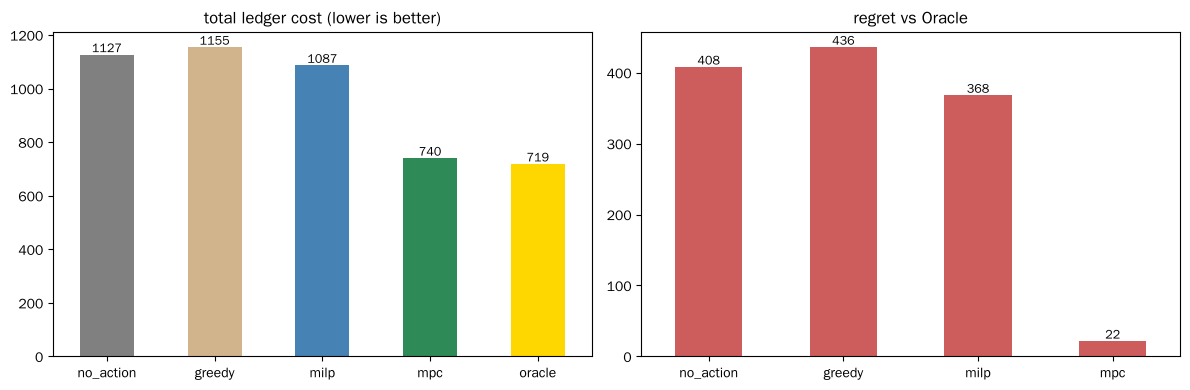

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tab["total_cost"].plot.bar(ax=axes[0], color=["gray", "tan", "steelblue", "seagreen", "gold"]); axes[0].set_title("total ledger cost (lower is better)")
tab.drop(index="oracle")["regret_vs_oracle"].plot.bar(ax=axes[1], color="indianred"); axes[1].set_title("regret vs Oracle")
for ax in axes:
    ax.tick_params(axis="x", rotation=0); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 6. 포트폴리오에 적는 실측값은 어디서 오는가

위 숫자는 설명용입니다. 면접에서 말하는 숫자는 아래 아티팩트에서 읽고, 각 파일의 `claim_status` 와 `mode` 를 함께 말합니다.

In [19]:
def load(p):
    p = ROOT / p
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

hold = load("reports/v2/holdout/h3_multiholdout.json")
prom = load("reports/v2/holdout/promoted_model.json")
llm = load("reports/v2/llm_value/incremental_value_borough.json")
mpc = load("reports/v2/mpc/policy_comparison.json")
weather = load("reports/weather_lift.json")

summary = []
if hold:
    a = hold["aggregate"]
    summary.append(("H3 zone-hour multi-holdout (promoted model)", f"WAPE {a['wape']['mean']:.4f} ± {a['wape']['std']:.4f} over {a['wape']['n']} windows, MASE {a['mase']['mean']:.3f}",
                    hold["claim_status"], hold["mode"], hold["artifact_id"]))
if prom:
    summary.append(("served model", f"{prom['algorithm']} / features {prom['feature_version']} / sklearn {prom['library_versions'].get('scikit-learn')}",
                    prom["claim_status"], prom["mode"], prom["artifact_id"]))
if llm:
    arms = llm["arms"]
    s1, s2 = llm["structured_event_lift_A1_minus_A0"], llm["llm_news_increment_A2_minus_A1"]
    summary.append(("borough-hour A0/A1/A2 (rule event vs LLM news)",
                    f"WAPE A0 {arms['A0_demand_calendar']['wape']:.4f} → A1 {arms['A1_plus_permitted']['wape']:.4f} → A2 {arms['A2_plus_llm_news']['wape']:.4f}; "
                    f"A1−A0 mean gain {s1['mean_gain']:.2f} trips/row CI {s1['ci_95']} ({s1['verdict']}); A2−A1 {s2['mean_gain']:.2f} ({s2['verdict']})",
                    llm["claim_status"], llm["mode"], llm["artifact_id"]))
if mpc:
    bp = mpc["by_policy"]
    summary.append(("MPC policy comparison", ", ".join(f"{k} {v['total_cost']:.2f}" for k, v in bp.items()) + f" (regret MPC {bp['mpc']['regret_vs_oracle']:.2f})",
                    mpc["claim_status"], mpc["mode"], mpc["artifact_id"]))
if weather:
    pl = weather["predictive_lift"]
    summary.append(("weather join (previous-day weather columns)",
                    f"WAPE {weather['baseline_demand_calendar']['wape']:.4f} → {weather['plus_weather']['wape']:.4f} ({weather['test_days']}, {weather['zones']} zones); "
                    f"mean gain {pl['mean_gain']:.4f} CI {pl['ci_95']} ({pl['verdict']})",
                    "measured (file has no claim_status field)", "not recorded in file", "reports/weather_lift.json"))

pd.DataFrame(summary, columns=["what", "value", "claim_status", "mode", "artifact"]).set_index("what")

,value,claim_status,mode,artifact
what,,,,
H3 zone-hour multi-holdout (promoted model),"WAPE 0.4974 ± 0.0074 over 3 windows, MASE 0.871",measured,historical_replay,reports/v2/holdout/h3_multiholdout.json
served model,hist_gradient_boosting / features dfv1 / sklea...,measured,historical_replay,reports/v2/holdout/promoted_model.json
borough-hour A0/A1/A2 (rule event vs LLM news),WAPE A0 0.0908 → A1 0.0883 → A2 0.0905; A1−A0 ...,measured,historical_replay,reports/v2/llm_value/incremental_value_borough...
MPC policy comparison,"no_action 1126.72, greedy 1154.66, milp 1086.8...",simulated,research,reports/v2/mpc/policy_comparison.json
weather join (previous-day weather columns),"WAPE 0.4868 → 0.4893 (2026-06-01..2026-06-30, ...",measured (file has no claim_status field),not recorded in file,reports/weather_lift.json


## 면접에서 말하는 순서 (요약)

1. **데이터**: Citi Bike 트립 CSV → 수집기가 불량 행을 사유별로 집계 → H3 zone × 시간으로 집계(departures / arrivals / net_flow).
2. **EDA**: 출퇴근 두 봉우리, 주말 오후 봉우리, 이벤트 날 특정 zone 의 급증. 충격은 "언제, 어디서" 가 핵심이라 zone × hour 히트맵으로 본다.
3. **피처**: 지연/롤링(B1) 위에 뉴스를 LLM 으로 구조화해 `available_at ≤ cutoff` 규칙으로 as-of 조인(B3), 그래프로 이웃 zone 에 전파(B4). 13시 행엔 0, 14시 행부터 값이 생기는 것이 누수 테스트.
4. **예측**: 시간 기준 holdout, seasonal naive 가 기준선. WAPE/MAE/MASE/OCS 를 전체와 이벤트 시간대로 나눠 본다. 합성에서는 B3/B4 가 크게 좋아지지만, 실측(NYC)에서는 규칙 기반 이벤트(A1)는 개선, LLM 뉴스 증분(A2−A1)은 음의 lift 였고 그대로 보고했다.
5. **최적화**: 예측 → 목표 재고 → greedy / MILP(단일 시점) → MPC(6시간 receding horizon). 다기간 시뮬레이션에서 MPC 가 부족을 크게 줄이고 Oracle 대비 regret 이 가장 작다. 비용 단위는 가정값(`sourced: false`)이라 `simulated` 로 표기.
6. **숫자 출처**: 모든 수치는 `reports/` 아티팩트의 `run_id`, `claim_status`, `mode` 와 함께 말한다.